# Die erste Objekterkennung auf einem Straßenbild
**Aufgabe 2 · YOLOv8n auf COCO-Bild 000000061181**

Wo sieht das Modell ein Auto? Wie sicher ist es sich? Und welche Objekte hat COCO für dasselbe Foto erfasst? Führe die Zellen von oben nach unten aus. Du kannst die gespeicherten Ergebnisse auch direkt ansehen.

## 1. Das Straßenbild ansehen
Betrachte zuerst das unveränderte Foto. Welche Objekte kannst du auch in der Ferne noch erkennen?

000000061181.jpg · 500 × 321 Pixel


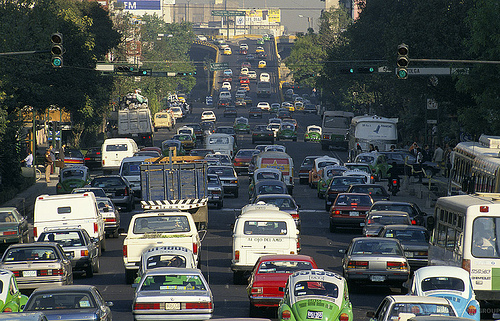

In [1]:
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import Image as NotebookImage, display
from matplotlib.patches import Patch, Rectangle
from matplotlib_inline.backend_inline import set_matplotlib_formats
from PIL import Image
from src.detect_road_objects import CLASSES, EXAMPLE, ROOT

set_matplotlib_formats("jpeg")
dataset = EXAMPLE.parents[2]
with Image.open(EXAMPLE) as photo:
    width, height = photo.size
    pixels = photo.convert("RGB")
print(f"{EXAMPLE.name} · {width} × {height} Pixel")
display(NotebookImage(filename=str(EXAMPLE)))

## 2. Die erste Vorhersage lesen
Diese Zelle startet denselben Detektor wie `python -m src.detect_road_objects`. Er schreibt eine Liste von Python-Dictionaries als JSON. Jedes Dictionary beschreibt **eine** Erkennung. Wir schauen uns die mit der höchsten Konfidenz an und schneiden den zugehörigen Bildbereich aus.

`name` ist die vorhergesagte Klasse, `confidence` der Modellscore. Die Box reicht in Pixeln von der linken oberen Ecke `(x1, y1)` bis zur rechten unteren Ecke `(x2, y2)`. Der Ursprung liegt links oben im Foto.

{'name': 'car',
 'class': 2,
 'confidence': 0.84956,
 'box': {'x1': 131.25342, 'y1': 266.52887, 'x2': 215.08687, 'y2': 321.0}}

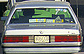

In [2]:
subprocess.run([sys.executable, "-m", "src.detect_road_objects"], cwd=ROOT,
               check=True, stdout=subprocess.DEVNULL)
report = json.loads((ROOT / "runs/task2" / f"{EXAMPLE.stem}.json").read_text())
predictions = report["images"][EXAMPLE.name]
if predictions:
    first = max(predictions, key=lambda obj: obj["confidence"])
    display(first)
    box = first["box"]
    display(pixels.crop((box["x1"], box["y1"], box["x2"], box["y2"])))

## 3. Modell und COCO-Annotationen vergleichen
Links siehst du die Modellvorhersagen, rechts die von COCO annotierten Objekte. Gleiche Farben stehen für gleiche Klassennamen. Das ist wichtig, weil YOLOv8n und der Vier-Klassen-Export unterschiedliche numerische IDs verwenden. Die COCO-Labels speichern Mittelpunkt und Größe relativ zur Bildgröße. Die nächste Zelle rechnet sie für die Darstellung in Pixel um.

In [3]:
class_names = yaml.safe_load((dataset / "dataset.yaml").read_text())["names"]
annotations = []
label_file = dataset / "labels/train" / f"{EXAMPLE.stem}.txt"
for line in label_file.read_text().splitlines():
    class_id, cx, cy, w, h = map(float, line.split())
    annotations.append({
        "name": class_names[int(class_id)],
        "box": {"x1": (cx - w/2) * width, "y1": (cy - h/2) * height,
                "x2": (cx + w/2) * width, "y2": (cy + h/2) * height},
    })

**Zum Ausprobieren:** Ändere `min_confidence` von `0.25` auf `0.60` und führe die folgenden beiden Zellen erneut aus. Welche Boxen verschwinden? Die gespeicherte Detektion enthält Vorhersagen ab 0,25. Die Anzeige filtert diese Liste, ohne das Modell erneut zu starten.

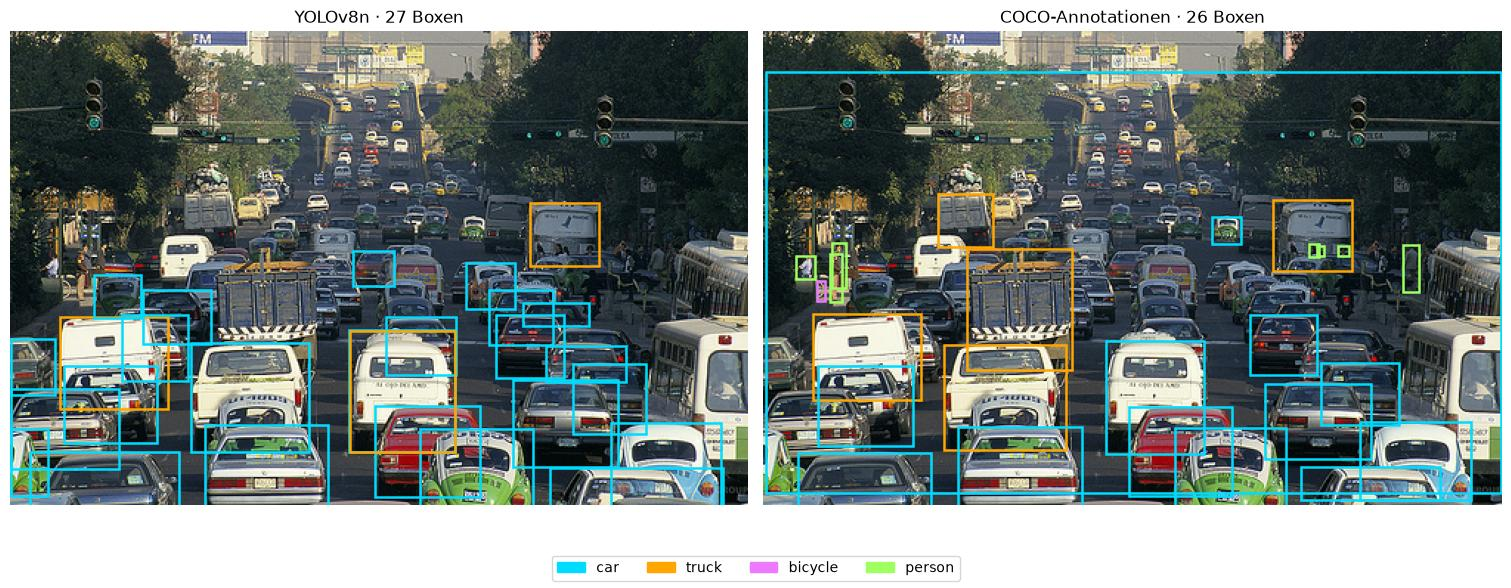

In [8]:
min_confidence = 0.25
assert 0.25 <= min_confidence <= 1, "Wähle einen Wert zwischen 0.25 und 1."
visible = [obj for obj in predictions if obj["confidence"] >= min_confidence]
colors = {"car": "#00dcff", "truck": "#ffa600", "bicycle": "#ed79ff", "person": "#9fff61"}

fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
for ax, objects, title in zip(axes, [visible, annotations], ["YOLOv8n", "COCO-Annotationen"]):
    ax.imshow(pixels)
    for obj in objects:
        b = obj["box"]
        ax.add_patch(Rectangle((b["x1"], b["y1"]), b["x2"] - b["x1"], b["y2"] - b["y1"],
                               fill=False, edgecolor=colors[obj["name"]], linewidth=1.8))
    ax.set_title(f"{title} · {len(objects)} Boxen")
    ax.axis("off")
fig.legend(handles=[Patch(color=colors[c], label=c) for c in CLASSES],
           loc="outside lower center", ncols=4)
plt.show()

## 4. Die Boxen pro Klasse zählen
Suche in der Tabelle die Klasse mit der größten Differenz. Prüfe dann im Bildpaar, wo zusätzliche Boxen auftauchen oder Objekte fehlen. Für eine Aussage über die Treffergenauigkeit müsstest du einzelne Vorhersagen räumlich mit den annotierten Objekten abgleichen.

In [5]:
from collections import Counter

counts = pd.DataFrame({
    "YOLOv8n": Counter(obj["name"] for obj in visible),
    "COCO": Counter(obj["name"] for obj in annotations),
}, index=list(CLASSES)).fillna(0).astype(int)
counts["Differenz (YOLO − COCO)"] = counts["YOLOv8n"] - counts["COCO"]
display(counts)

,YOLOv8n,COCO,Differenz (YOLO − COCO)
car,24,13,11
truck,3,5,-2
bicycle,0,1,-1
person,0,7,-7
